## 課題06レポート
新しい空のNotebookを作り、必要なコードを整理・改善しながら、手順がわかる順序で組み直し、テンプレートからグラフを作成し、気づいたことなどを書きまとめる。

https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis


In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
#テンプレートから置き換え。
import csv
import matplotlib.pyplot as plt


with open("order_products__prior.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))
order = data#グラフ完成後に商品一覧表を作ったためdataと同じような内容を使用したく=でつないだ。
print("購入履歴の総行数：", len(data))
print("最初の注文ID：",data[0]["order_id"])
print( "最初の商品ID：",data[0]["product_id"])

購入履歴の総行数： 32434489
最初の注文ID： 2
最初の商品ID： 33120


下準備にもう１つ名前用のcsvも読み込んでおく。

products.csvは商品IDに対応する具体的な名前が載っている。


In [3]:
import csv
import matplotlib.pyplot as plt


with open("products.csv", encoding="utf-8-sig", newline="") as file:
    products = list(csv.DictReader(file))

フォントを日本語対応させるために使用。

%pip install matplotlib-fontja
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Yu Gothic"
https://www.r-jc.jp/news-blog/2029/matplotlib%E3%81%AE%E4%BD%BF%E3%81%84%E6%96%B9%E3%81%A8%E6%97%A5%E6%9C%AC%E8%AA%9E%E6%96%87%E5%AD%97%E5%8C%96%E3%81%91%E5%AF%BE%E7%AD%96os%E5%88%A5colab312%E5%AF%BE%E5%BF%9C/#sec-1


In [4]:
%pip install matplotlib-fontja

Note: you may need to restart the kernel to use updated packages.


## 売り上げが高かった商品一覧表　60/49688品


In [5]:
%pip install pandas
import pandas as pd 

Note: you may need to restart the kernel to use updated packages.


In [6]:
# テンプレートweek05
import pandas as pd
df = pd.read_csv('products.csv')

from collections import Counter#from collectionsを後から追加。AI「Counter は collections というモジュールの中にあるため」←よくわかっていない。
count = Counter(row["product_id"] for row in order)

columns = ['product_id', 'product_name']
sina = df[columns]#dataは後で使ったため被りが発生したのでsinaという名称に変更した。

print(f"全商品数：{len(sina)}件")

# 購入回数を追加する
sina['購入回数'] = sina['product_id'].astype(str).map(count)

# 購入回数が10000回を超える商品だけ表示
sina = sina[sina['購入回数'] > 50000]

display(sina)#テンプレートで動かなかったため検索した。data.head()	セルの最後にある場合 display(data.head())	セルの途中でも表示できる
# 商品合計数の表示
print(f"売り上げ良商品数：{len(sina)}件")

全商品数：49688件


,product_id,product_name,購入回数
4604,4605,Yellow Onions,73167
4919,4920,Seedless Red Grapes,82689
5076,5077,100% Whole Wheat Bread,60816
5875,5876,Organic Lemon,87746
8276,8277,Apple Honeycrisp Organic,85020
8517,8518,Organic Red Onion,66986
9075,9076,Blueberries,55946
10748,10749,Organic Red Bell Pepper,57485
12340,12341,Hass Avocados,50221
13175,13176,Bag of Organic Bananas,379450


売り上げ良商品数：60件


## 商品売り上げTOP10


商品idの大きさではなく、回数であるためcouterを使用する必要がある。途中までlenを使用していた。

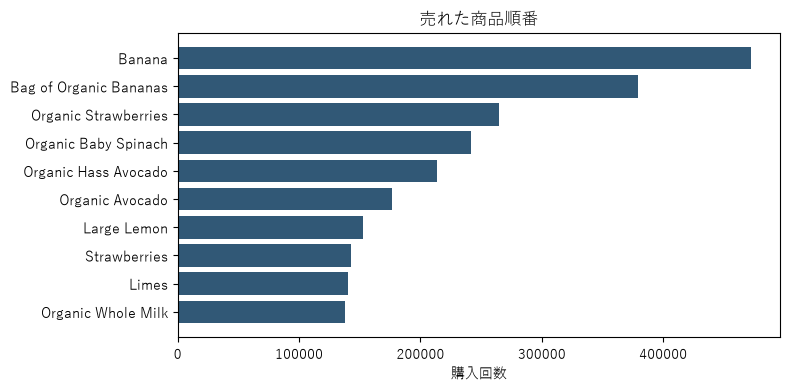

In [7]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Yu Gothic"
from collections import Counter#from collectionsを後から追加。AI「Counter は collections というモジュールの中にあるため」←よくわかっていない。
count = Counter(row["product_id"] for row in data)
top5 = list(reversed(count.most_common(10)))#count.mostではなく、AIによると_commonまで必要だった。このまま作成した場合多い順に下に表示されるためreversedを先につけた。
#reversed(...) が作るオブジェクトは「1度中身を取り出すと、消えて空になる」という特殊な性質を持っている。list(...) で囲んで普通のリスト型に変換して保存しておく必要がある。

idtoname = {p["product_id"]: p["product_name"] for p in products}#商品idと商品名を入れ替えようとしたが直接入れ替える方法では失敗したためAIにより命名して一度固定する手段をとる必要があった。

names = [idtoname.get(row[0]) for row in top5]#「名称（キー）」と「値」がセットになっていたが商品コードの回数になったためrow[1個目,2個目]となり、プログラミングでいう0と1になってしまった。
#id_to_name.get(...)：辞書（変換表）から値を取り出す命令。AIによるとこれが無かったため入れ替えることはそもそもできていなかったとのこと。
population = [(row[1]) for row in top5]

plt.figure(figsize=(8, 4))
plt.barh(names, population, color="#315876")
plt.xlabel("購入回数")
plt.title("売れた商品順番")
plt.tight_layout()
plt.show()#全部を高い順に並べることも出来るらしい。

最も購入数が多かったのは「Banana（バナナ）」であり、約47万回の購入実績を記録している。これに次ぐ2位には「Bag of Organic Bananas（有機バナナ）」が約38万回で、同系統の商品を合算すると総購入数は85万回を超えている。このことから、バナナはこの店では大量仕入れすると利益が見込める。全体ととおしてオーガニック系統の商品に人気がある。

## 今後の目標。 

week05で行った自転車レンタル数シミュレーションゲームをこのスーパーの売上csvで作りたいと考えている。人気商品上から

60個を商品名＿個数=[]で商品棚を作り、

所持金-個数*商品名＿仕入れ値=?の仕組みで商品を補充し、

客が来る様子を再現customers=random.randint(1, 50)などで複数のお客が来る様子を再現し、

import randam からcsvのレシート情報をランダムで読み取り、

csvの列名と商品が一致したら、

商品名＿個数=[]の商品棚から売れた個数*-1され、

売れた個数*商品名_売り上げで、所持金を+させたい。

python上ではwhile関数を使用してif answer.lower() != "y" and answer.lower() != "yes":
      breakで!=でyesまたは打ちやすいキーなどを考えながら繰り返しのゲームを作成を目指したい。

このゲームを最後につけることでデータを見せるだけでなく、売り上げや需要についての関心や興味を持ってもらうことが期待される。